Saving Sample - Superstore.csv to Sample - Superstore (1).csv
Rows removed during cleaning: 0
Cleaned rows: 9,994
Columns: 24
Total sales: $2,297,200.86
Total profit: $286,397.02
Date range: 2014-01-03 to 2017-12-30

Data types:


,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object



Missing values:


,Missing Values
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0



Top 10 products by units sold:


,Product Name,Units_Sold,Sales
1499,Staples,215,755.470
1493,Staple envelope,170,1686.812
537,Easy-staple paper,150,2504.192
1500,Staples in misc. colors,86,478.812
942,KI Adjustable-Height Table,74,4552.641
1511,Storex Dura Pro Binders,71,278.586
259,Avery Non-Stick Binders,71,217.316
699,GBC Premium Transparent Covers with Diagonal L...,67,780.456
1450,"Situations Contoured Folding Chairs, 4/Set",64,3641.274
1497,Staple-based wall hangings,62,422.288


... (2 outputs left out)


Top 10 customers by sales:


,Customer ID,Sales,Orders
700,SM-20320,25043.050,5
741,TC-20980,19052.218,5
621,RB-19360,15117.339,6
730,TA-21385,14595.620,4
6,AB-10105,14473.571,10
434,KL-16645,14175.229,12
669,SC-20095,14142.334,9
327,HL-15040,12873.298,6
683,SE-20110,12209.438,11
131,CC-12370,12129.072,5



Monthly sales:


,Year-Month,Sales
0,2014-01,14236.8950
1,2014-02,4519.8920
2,2014-03,55691.0090
3,2014-04,28295.3450
4,2014-05,23648.2870
5,2014-06,34595.1276
6,2014-07,33946.3930
7,2014-08,27909.4685
8,2014-09,81777.3508
9,2014-10,31453.3930


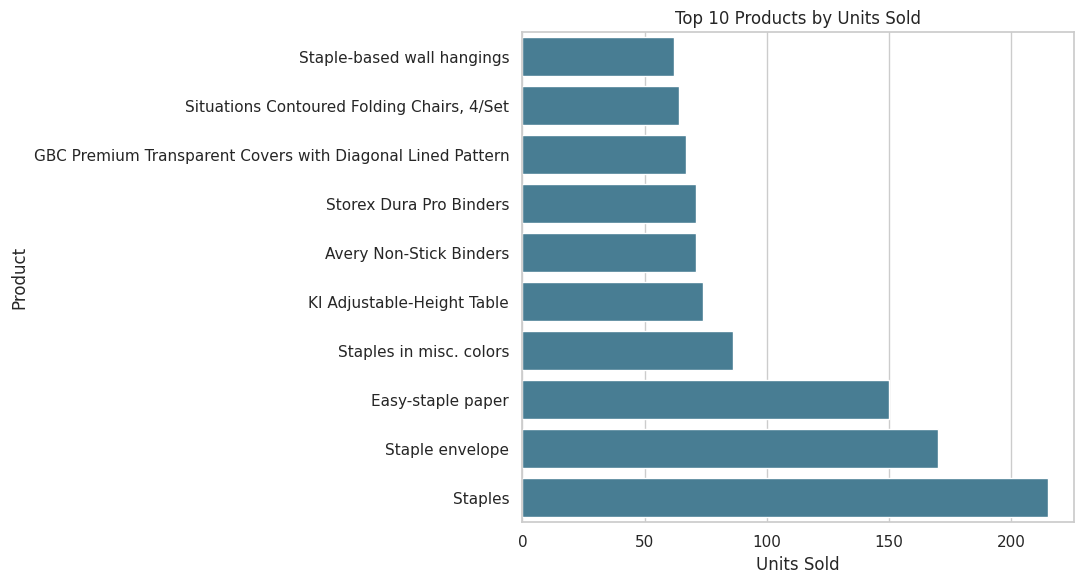

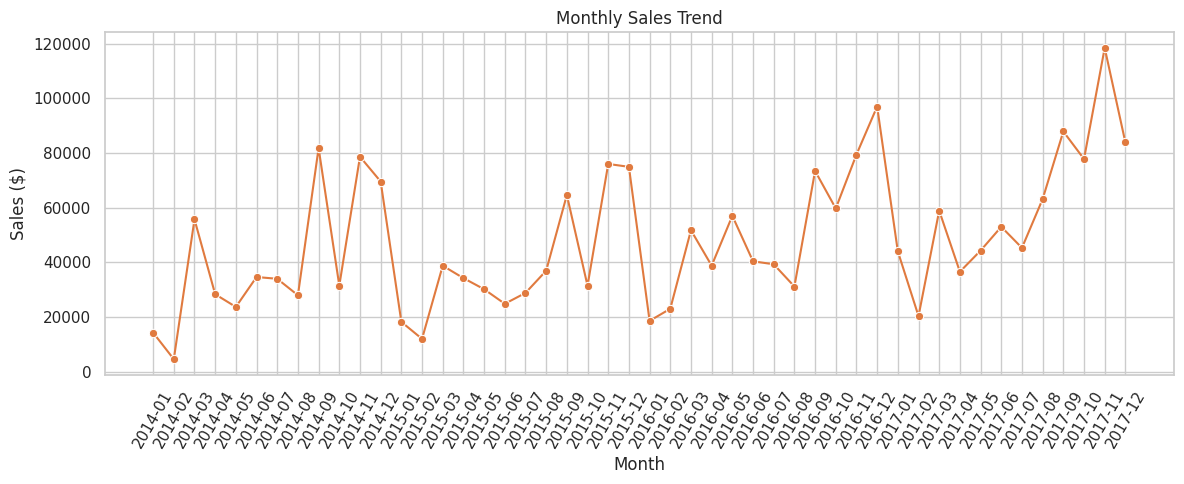

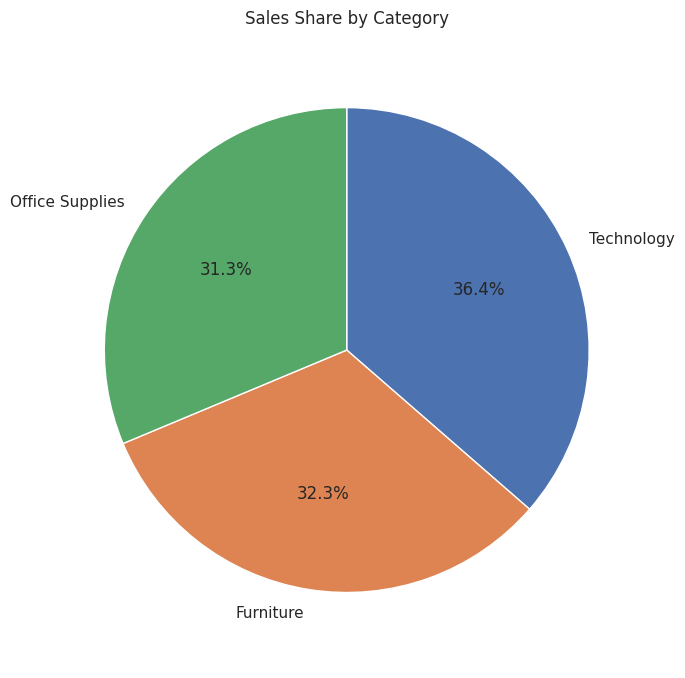

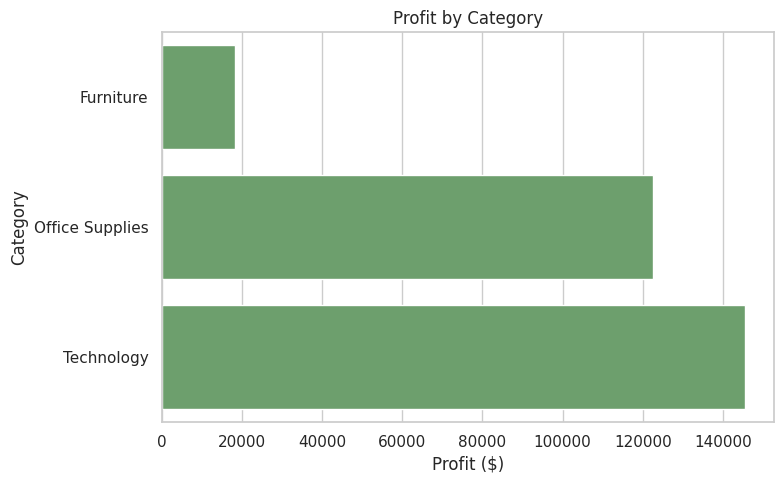


Cleaned dataset saved to: /content/results/superstore_cleaned.csv
Charts saved to: /content/results/charts


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files


# Upload the dataset from your computer
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded.")

# Use the uploaded file
input_filename = next(iter(uploaded))
raw_file = Path("/content") / input_filename

# Create folders for the results
results_dir = Path("/content/results")
charts_dir = results_dir / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)


def load_and_clean(path):
    """Load and clean the Superstore sales dataset."""
    try:
        df = pd.read_csv(path, encoding="utf-8-sig")
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding="latin1")
    df.columns = df.columns.str.strip()

    required_columns = {
        "Order Date",
        "Sales",
        "Quantity",
        "Category",
        "Product Name",
        "Customer ID",
    }
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"Required columns are missing: {sorted(missing_columns)}"
        )

    rows_before_cleaning = len(df)

    # Remove exact duplicate rows
    df = df.drop_duplicates().copy()

    # Convert date columns
    for column in ["Order Date", "Ship Date"]:
        if column in df.columns:
            df[column] = pd.to_datetime(df[column], errors="coerce")

    # Convert numeric columns
    for column in ["Sales", "Quantity", "Discount", "Profit"]:
        if column in df.columns:
            df[column] = pd.to_numeric(df[column], errors="coerce")

    # Fill missing labels
    df["Category"] = df["Category"].fillna("Unspecified")
    df["Product Name"] = df["Product Name"].fillna("Unspecified")
    df["Customer ID"] = df["Customer ID"].fillna("Unspecified")

    # Remove rows missing essential fields
    df = df.dropna(subset=["Order Date", "Sales", "Quantity"])

    # Quantity must be positive. Negative sales are retained because
    # they may represent returns or adjustments.
    df = df[df["Quantity"] > 0].copy()

    # Add date fields for analysis
    df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
    df["Order Year"] = df["Order Date"].dt.year.astype("int64")
    df["Order Month"] = df["Order Date"].dt.month.astype("int64")

    removed_rows = rows_before_cleaning - len(df)
    print(f"Rows removed during cleaning: {removed_rows:,}")

    return df


def summarize_data(df):
    """Create summary tables for sales, products, and customers."""
    monthly_sales = (
        df.groupby("Year-Month", as_index=False)["Sales"]
        .sum()
        .sort_values("Year-Month")
    )

    category_sales = (
        df.groupby("Category", as_index=False)["Sales"]
        .sum()
        .sort_values("Sales", ascending=False)
    )

    top_products = (
        df.groupby("Product Name", as_index=False)
        .agg(
            Units_Sold=("Quantity", "sum"),
            Sales=("Sales", "sum"),
        )
        .sort_values(
            ["Units_Sold", "Sales"],
            ascending=False,
        )
        .head(10)
    )

    if "Order ID" in df.columns:
        top_customers = (
            df.groupby("Customer ID", as_index=False)
            .agg(
                Sales=("Sales", "sum"),
                Orders=("Order ID", "nunique"),
            )
            .sort_values("Sales", ascending=False)
            .head(10)
        )
    else:
        top_customers = (
            df.groupby("Customer ID", as_index=False)
            .agg(
                Sales=("Sales", "sum"),
                Orders=("Sales", "size"),
            )
            .sort_values("Sales", ascending=False)
            .head(10)
        )

    return monthly_sales, category_sales, top_products, top_customers


# Load and clean the data
df = load_and_clean(raw_file)

# Display basic information
print(f"Cleaned rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Total sales: ${df['Sales'].sum():,.2f}")

if "Profit" in df.columns:
    print(f"Total profit: ${df['Profit'].sum():,.2f}")

print(
    "Date range:",
    df["Order Date"].min().date(),
    "to",
    df["Order Date"].max().date(),
)

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Values"))

# Create analysis tables
monthly_sales, category_sales, top_products, top_customers = summarize_data(df)

print("\nTop 10 products by units sold:")
display(top_products)

print("\nSales by category:")
display(category_sales)

print("\nTop 10 customers by sales:")
display(top_customers)

print("\nMonthly sales:")
display(monthly_sales)


# Chart 1: Top products by units sold
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=top_products.sort_values("Units_Sold"),
    x="Units_Sold",
    y="Product Name",
    ax=ax,
    color="#3b82a0",
)
ax.set_title("Top 10 Products by Units Sold")
ax.set_xlabel("Units Sold")
ax.set_ylabel("Product")
plt.tight_layout()
plt.savefig(charts_dir / "01_top_products.png", dpi=160)
plt.show()


# Chart 2: Monthly sales trend
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=monthly_sales,
    x="Year-Month",
    y="Sales",
    marker="o",
    ax=ax,
    color="#e07a3f",
)
ax.set_title("Monthly Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Sales ($)")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(charts_dir / "02_monthly_sales.png", dpi=160)
plt.show()


# Chart 3: Sales share by category
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    category_sales["Sales"],
    labels=category_sales["Category"],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
)
ax.set_title("Sales Share by Category")
ax.axis("equal")
plt.tight_layout()
plt.savefig(charts_dir / "03_category_share.png", dpi=160)
plt.show()


# Chart 4: Profit by category, if profit data is available
if "Profit" in df.columns:
    profit_by_category = (
        df.groupby("Category", as_index=False)["Profit"]
        .sum()
        .sort_values("Profit")
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(
        data=profit_by_category,
        x="Profit",
        y="Category",
        ax=ax,
        color="#65a765",
    )
    ax.set_title("Profit by Category")
    ax.set_xlabel("Profit ($)")
    ax.set_ylabel("Category")
    plt.tight_layout()
    plt.savefig(charts_dir / "04_profit_by_category.png", dpi=160)
    plt.show()


# Save the cleaned CSV
cleaned_file = results_dir / "superstore_cleaned.csv"
df.to_csv(cleaned_file, index=False, encoding="utf-8-sig")

print(f"\nCleaned dataset saved to: {cleaned_file}")
print(f"Charts saved to: {charts_dir}")


# Download the cleaned CSV to your computer
files.download(str(cleaned_file))